In [24]:
import geopandas as gpd
import osmnx as ox
from shapely.geometry import Polygon
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from collections import Counter

In [32]:
roads_gdf = gpd.read_file('datos/2_Estructura_via/estructura_via_completa/MVI.geojson')
roads_gdf["id_mvi"] = roads_gdf["MVICIV"].astype(str) + "_" + roads_gdf["MVISVIA"].str.replace(" ", "")
roads_gdf['contador'] = roads_gdf.groupby('id_mvi').cumcount() + 1
roads_gdf['id_mvi'] = roads_gdf['id_mvi'] + '.' + roads_gdf['contador'].astype(str)
roads_gdf = (
    roads_gdf.explode(ignore_index=True)          # if shapefile has split segments
       .dissolve(by='id_mvi')               # merge all segments of same road
       .reset_index()
)
roads_gdf['road_id'] = roads_gdf['id_mvi']
# roads_gdf = roads_gdf.to_crs(epsg=3116)
roads_gdf['buffer'] = roads_gdf.geometry.buffer(0.01)
# roads_gdf = roads_gdf.to_crs(epsg=)

minx, miny, maxx, maxy = roads_gdf['buffer'].total_bounds
# pad = 200  # extra margin
north, south = maxy, miny
east, west   = maxx, minx

bbox = (west, south, east, north)

tags = {'building': True}
buildings = ox.features.features_from_bbox(
    bbox=bbox, tags=tags  # Pass bbox as a tuple
)#.to_crs(epsg=3116)

/tmp/ipykernel_24546/1512925411.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  roads_gdf['buffer'] = roads_gdf.geometry.buffer(0.01)


In [36]:
roads_gdf = roads_gdf.to_crs(epsg=3116)
roads_gdf['buffer'] = roads_gdf.geometry.buffer(100)

In [37]:
buildings = buildings.to_crs(epsg=3116)

In [38]:
buildings = buildings.loc[
    buildings.geometry.type.isin(['Polygon','MultiPolygon'])
    & buildings['building'].notna(),
    ['building','geometry']
].rename(columns={'building':'bld_type'})

In [40]:
roads_buf = roads_gdf.set_geometry('buffer')[['road_id','buffer']]

In [41]:
joined = gpd.sjoin(
    roads_buf,
    buildings,
    how='left',
    predicate='intersects'
)

In [42]:
counts = (
    joined
      .dropna(subset=['bld_type'])
      .groupby(['road_id','bld_type'], sort=False)
      .size()
      .reset_index(name='count')
)

In [44]:
df_counts = (
    counts
      .pivot(index='road_id', columns='bld_type', values='count')
      .fillna(0)
      .astype(int)
      .reset_index()
)

In [49]:
import os

In [51]:
file_output_name = "datos_procesados/buildings/"
os.makedirs(file_output_name, exist_ok=True)
df_counts.to_csv(f'{file_output_name}roads_buildings.csv', index=False)

In [15]:
tags = {'building': True}
gdf = ox.features.features_from_place('Bogota', tags)

In [29]:
gdf.loc[gdf.building=='yes']

geometry  \
element id                                                              
node    267583546                            POINT (-74.03898 4.6797)   
        374448575                           POINT (-74.04507 4.72983)   
        504805822                           POINT (-74.04541 4.73673)   
        662223781                           POINT (-74.10473 4.66774)   
        822059744                           POINT (-74.07245 4.60543)   
...                                                               ...   
way     1394003216  POLYGON ((-74.14355 4.68504, -74.14351 4.68501...   
        1394003229  POLYGON ((-74.13813 4.67116, -74.13808 4.67111...   
        1394003249  POLYGON ((-74.13725 4.67192, -74.13715 4.67177...   
        1394027764  POLYGON ((-74.13398 4.60208, -74.13394 4.60205...   
        1394027765  POLYGON ((-74.13452 4.60244, -74.13454 4.60241...   

                       amenity bicycle_parking building covered  \
element id                                                        
node    267583546          NaN             NaN      yes     NaN   
        374448575          NaN             NaN      yes     NaN   
        504805822          NaN             NaN      yes     NaN   
        662223781          NaN             NaN      yes     NaN   
        822059744          NaN             NaN      yes     NaN   
...                        ...             ...      ...     ...   
way     1394003216      police             NaN      yes     NaN   
        1394003229      police             NaN      yes     NaN   
        1394003249  restaurant             NaN      yes     NaN   
        1394027764         NaN             NaN      yes     NaN   
        1394027765         NaN             NaN      yes     NaN   

                                    name cuisine capacity  fee  \
element id                                                       
node    267583546        Torre Santander     NaN      NaN  NaN   
        374448575               Soko 147  burger      NaN  NaN   
        504805822                    NaN     NaN      NaN  NaN   
        662223781   Conjunto San Nicolas     NaN      NaN  NaN   
        822059744                  IDEAM     NaN      NaN  NaN   
...                                  ...     ...      ...  ...   
way     1394003216         CAI Versalles     NaN      NaN  NaN   
        1394003229         CAI Santander     NaN      NaN  NaN   
        1394003249          Zona Gourmet     NaN      NaN  NaN   
        1394027764                   NaN     NaN      NaN  NaN   
        1394027765                   NaN     NaN      NaN  NaN   

                                        operator  ... direction highway  \
element id                                        ...                     
node    267583546                            NaN  ...       NaN     NaN   
        374448575                            NaN  ...       NaN     NaN   
        504805822                            NaN  ...       NaN     NaN   
        662223781                            NaN  ...       NaN     NaN   
        822059744                            NaN  ...       NaN     NaN   
...                                          ...  ...       ...     ...   
way     1394003216  Policía Nacional de Colombia  ...       NaN     NaN   
        1394003229  Policía Nacional de Colombia  ...       NaN     NaN   
        1394003249                           NaN  ...       NaN     NaN   
        1394027764                           NaN  ...       NaN     NaN   
        1394027765                           NaN  ...       NaN     NaN   

                   architect:wikidata building:architecture exhibit library  \
element id                                                                    
node    267583546                 NaN                   NaN     NaN     NaN   
        374448575                 NaN                   NaN     NaN     NaN   
        504805822                 NaN                   NaN     NaN     NaN   
        6

In [25]:
Counter(gdf.building)

Counter({'yes': 56819,
         'house': 6323,
         'apartments': 6274,
         'residential': 5864,
         'commercial': 1958,
         'school': 1072,
         'retail': 859,
         'university': 745,
         'semidetached_house': 673,
         'roof': 624,
         'construction': 527,
         'terrace': 328,
         'warehouse': 219,
         'office': 214,
         'public': 169,
         'industrial': 151,
         'hospital': 133,
         'detached': 105,
         'church': 94,
         'kindergarten': 64,
         'hotel': 50,
         'college': 39,
         'garage': 35,
         'greenhouse': 32,
         'abandoned': 30,
         'civic': 27,
         'parking': 26,
         'chapel': 25,
         'hangar': 22,
         'guardhouse': 17,
         'fire_station': 17,
         'temple': 17,
         'storage_tank': 16,
         'service': 15,
         'bus_station': 13,
         'transportation': 12,
         'government': 12,
         'pavilion': 8,
         'sh

<Axes: >

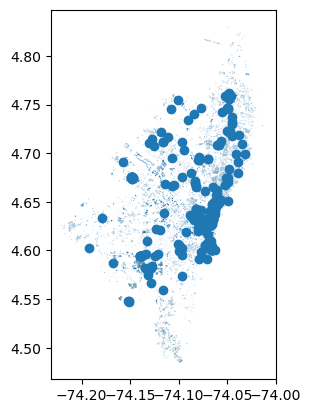

In [17]:
gdf.plot()

In [12]:
bbox

(964452.1279480599, 910468.8520779085, 1009850.4900638091, 1026888.1843710106)

In [3]:
minx, miny, maxx, maxy = roads_gdf['buffer'].total_bounds
pad = 200  # extra margin
north, south = maxy+pad, miny-pad
east, west   = maxx+pad, minx-pad

In [ ]:
bbox = (west, south, east, north)

In [13]:
tags = {'building': True}
buildings = ox.features_from_bbox(
    bbox=bbox, tags=tags  # Pass bbox as a tuple
)#.to_crs(epsg=3116)

RuntimeError: Unable to determine UTM CRS

In [5]:
ox.__version__

'2.0.4'

In [ ]:
!pip install --upgrade osmnx

In [ ]:
road_df['centroid'] = road_df.geometry.centroid

# 4. Extract latitude and longitude
road_df['latitude'] = road_df.centroid.y
road_df['longitude'] = road_df.centroid.x

# 5. (Optional) Create a new GeoDataFrame of centroids
road_df_centroids = gpd.GeoDataFrame(
    road_df.drop(columns='geometry'),
    geometry=road_df['centroid'],
    crs='EPSG:4326'
)

In [ ]:
road_df.shape

In [ ]:
import osmnx as ox
from osmnx import geometries

In [ ]:
ox.

In [ ]:
road_df_m = road_df.to_crs(epsg=3116)
road_df_m['buffer'] = road_df_m.geometry.buffer(100)

# 3. Fetch all buildings in the overall bbox extended by 100 m
minx, miny, maxx, maxy = road_df_m['buffer'].total_bounds
# pad bbox slightly
pad = 200
north, south, east, west = maxy+pad, miny-pad, maxx+pad, minx-pad
# pull OSM building footprints
tags = {'building': True}
gdf_bld = ox.geometries.geometries_from_bbox(
    north, south, east, west, tags=tags
).to_crs(epsg=3116)

# keep only polygons and a 'bld_type' column
gdf_bld = gdf_bld.loc[
    gdf_bld.geometry.type.isin(['Polygon','MultiPolygon'])
    & gdf_bld['building'].notna(),
    ['building','geometry']
].rename(columns={'building':'bld_type'})

# 4. Spatial‐join: which buildings intersect which point‐buffers?
road_df_m = road_df_m.set_geometry('buffer')
joined = gpd.sjoin(
    road_df_m[['pt_id','buffer']],
    gdf_bld,
    how='left',
    predicate='intersects'
)

# 5. Count by (pt_id, bld_type)
counts = (
    joined
      .dropna(subset=['bld_type'])       # remove points with no building match
      .groupby(['pt_id','bld_type'])
      .size()
      .reset_index(name='count')
)

# 6. Pivot to wide format: one row per pt_id, one column per building type
df_counts = counts.pivot(
    index='pt_id',
    columns='bld_type',
    values='count'
).fillna(0).astype(int).reset_index()
